# TC5061 — Actividad 2: Dataset & Notebook Baseline

**Rolando Calderón Carballo — A01840537**
**Operaciones de aprendizaje automático (Gpo 10)**

**Dataset:** Medical Appointment No-Shows (Kaggle, ~110k citas médicas reales, Brasil 2016).

**¿Por qué este dataset?** Responde a un proyector que estamos desarrollando en mi empresa.

In [26]:
# Librerías de análisis y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Semilla global para reproducibilidad
SEED = 42
np.random.seed(SEED)

print("pandas", pd.__version__)

pandas 3.0.6


In [27]:
# Carga del dataset descargado de Kaggle
df = pd.read_csv("KaggleV2-May-2016.csv")

print(f"Registros: {df.shape[0]:,}  |  Variables: {df.shape[1]}")
df.head()

Registros: 110,527  |  Variables: 14


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [28]:
# Tipos de dato y nulos por columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  str    
 3   ScheduledDay    110527 non-null  str    
 4   AppointmentDay  110527 non-null  str    
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  str    
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  str    
dtypes: float64(1), int64(8), str(5)
memory usage: 17.6 MB


**Estructura del dataset:** 110,527 registros (citas médicas) y 14 variables.

| Grupo | Variables | Significado |
|---|---|---|
| Identificadores | `PatientId`, `AppointmentID` | ID del paciente (se repite: un paciente, varias citas) y de la cita |
| Demográficas | `Gender`, `Age`, `Neighbourhood` | Perfil del paciente y barrio de la clínica |
| Agendamiento | `ScheduledDay`, `AppointmentDay` | Fecha en que se **solicitó** la cita vs fecha de la cita |
| Condición social/salud | `Scholarship`, `Hipertension`, `Diabetes`, `Alcoholism`, `Handcap` | Beca social brasileña y comorbilidades (binarias) |
| Recordatorio | `SMS_received` | Si recibió SMS recordatorio (binaria) |
| **Objetivo** | `No-show` | **"Yes" = NO asistió a la cita; "No" = sí asistió** |

**Observaciones iniciales:**
1. Las fechas vienen como texto → habrá que convertirlas; su diferencia (días de espera
   entre agendar y la cita) es probablemente la variable más valiosa y no existe aún.
2. `PatientId` es `float64` — un identificador como decimal es un tipo incorrecto a corregir.
3. La variable objetivo tiene semántica invertida ("No" = asistió): hay que codificarla
   con cuidado para no entrenar el modelo al revés.
4. `Handcap` debería ser binaria pero habrá que verificar sus valores reales.

In [29]:
# Estadísticas descriptivas de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PatientId,110527.0,1.474963e+14,2.560949e+14,3.921784e+04,4.172614e+12,3.173184e+13,9.439172e+13,9.999816e+14
AppointmentID,110527.0,5.675305e+06,7.129575e+04,5.030230e+06,5.640286e+06,5.680573e+06,5.725524e+06,5.790484e+06
Age,110527.0,3.708887e+01,2.311020e+01,-1.000000e+00,1.800000e+01,3.700000e+01,5.500000e+01,1.150000e+02
Scholarship,110527.0,9.826558e-02,2.976748e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Hipertension,110527.0,1.972459e-01,3.979213e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Diabetes,110527.0,7.186479e-02,2.582651e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Alcoholism,110527.0,3.039981e-02,1.716856e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Handcap,110527.0,2.224796e-02,1.615427e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
SMS_received,110527.0,3.210256e-01,4.668727e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00


Tasa de ausentismo (no-show): 20.2%


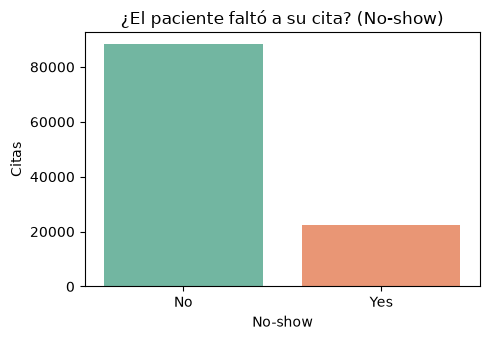

In [30]:
# Balance de la variable objetivo
# Ojo con la semántica: "Yes" = el paciente NO se presentó
tasa_noshow = (df["No-show"] == "Yes").mean()
print(f"Tasa de ausentismo (no-show): {tasa_noshow:.1%}")

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="No-show", hue="No-show", palette="Set2", legend=False, ax=ax)
ax.set_title("¿El paciente faltó a su cita? (No-show)")
ax.set_ylabel("Citas")
plt.tight_layout()
plt.show()

**Lectura de las estadísticas descriptivas:**

1. **`Age` tiene un mínimo de −1**: valor imposible → dato inválido a tratar en limpieza.
   El máximo de 115 es extremo pero plausible; se evaluará como outlier.
2. **`Handcap` va de 0 a 4**: no es binaria como sugiere la documentación del dataset,
   sino un grado de discapacidad → se tratará como categórica.
3. **Desbalance del objetivo:** 20.2% de no-show. Un clasificador trivial que prediga
   "todos asisten" lograría 79.8% de accuracy — ese es el piso real contra el cual
   evaluar el baseline, y la razón para no fiarse de la accuracy como métrica única.
4. Las comorbilidades son de baja prevalencia (diabetes 7%, alcoholismo 3%), consistente
   con población general.

In [31]:
# Convertimos las fechas (vienen como texto) para explorar el tiempo de espera:
# días entre que se SOLICITÓ la cita y el día de la cita.
# ScheduledDay trae hora exacta y AppointmentDay viene a medianoche, así que
# normalizamos ambas a fecha (00:00) antes de restar.
df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"])
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"])

df["DiasEspera"] = (df["AppointmentDay"].dt.normalize()
                    - df["ScheduledDay"].dt.normalize()).dt.days

print(df["DiasEspera"].describe())
print(f"\nCitas con espera negativa (¿cita antes de agendarla?): "
      f"{(df['DiasEspera'] < 0).sum()}")

count    110527.000000
mean         10.183702
std          15.254996
min          -6.000000
25%           0.000000
50%           4.000000
75%          15.000000
max         179.000000
Name: DiasEspera, dtype: float64

Citas con espera negativa (¿cita antes de agendarla?): 5


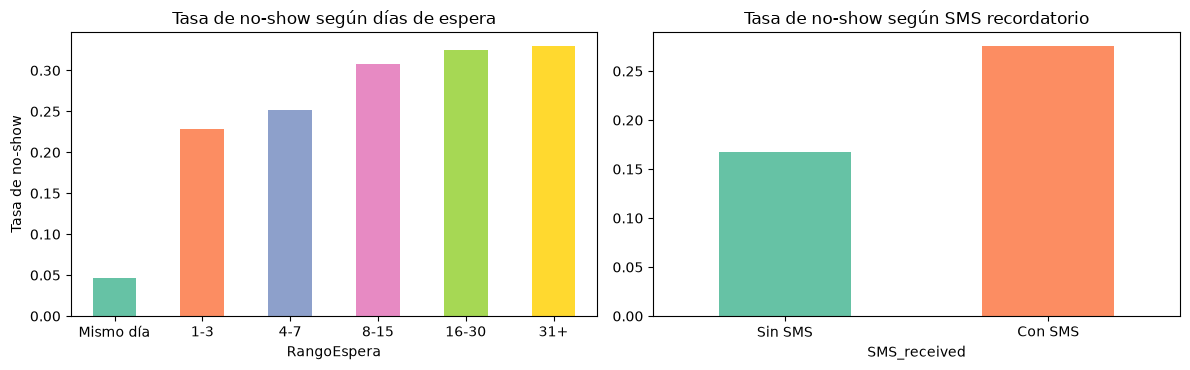

RangoEspera
Mismo día    0.046
1-3          0.229
4-7          0.252
8-15         0.308
16-30        0.325
31+          0.330
Name: No-show, dtype: float64
SMS_received
0    0.167
1    0.276
Name: No-show, dtype: float64


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

# Tasa de no-show por rango de días de espera
bins = [-1, 0, 3, 7, 15, 30, 200]
labels = ["Mismo día", "1-3", "4-7", "8-15", "16-30", "31+"]
df["RangoEspera"] = pd.cut(df["DiasEspera"], bins=bins, labels=labels)
tasa_espera = df.groupby("RangoEspera", observed=True)["No-show"].apply(
    lambda s: (s == "Yes").mean())
tasa_espera.plot(kind="bar", color=sns.color_palette("Set2"), ax=axes[0])
axes[0].set_title("Tasa de no-show según días de espera")
axes[0].set_ylabel("Tasa de no-show")
axes[0].tick_params(axis="x", rotation=0)

# Tasa de no-show según recordatorio SMS
tasa_sms = df.groupby("SMS_received")["No-show"].apply(lambda s: (s == "Yes").mean())
tasa_sms.plot(kind="bar", color=sns.color_palette("Set2"), ax=axes[1])
axes[1].set_title("Tasa de no-show según SMS recordatorio")
axes[1].set_xticklabels(["Sin SMS", "Con SMS"], rotation=0)

plt.tight_layout()
plt.show()

print(tasa_espera.round(3))
print(tasa_sms.round(3))

**Hallazgos del EDA:**

1. **El tiempo de espera es el factor dominante:** la tasa de no-show escala de 4.6% en
   citas del mismo día a 33% cuando la espera supera el mes. `DiasEspera` ni siquiera
   existía en el dataset original — se construyó a partir de las dos fechas — y es la
   señal más fuerte encontrada.
2. **El SMS:** las citas con recordatorio SMS muestran *mayor* ausentismo
   (27.6%) que las que no lo recibieron (16.7%). No es que el SMS provoque faltas: los
   recordatorios se enviaban principalmente a citas agendadas con mucha anticipación, y
   la espera larga es la verdadera causa del ausentismo. Es un ejemplo de correlación
   contaminada por una variable de confusión (confounder), y una advertencia directa
   contra leer los coeficientes de un modelo como relaciones causales.
3. **Calidad de datos:** se detectaron 5 citas con espera negativa (agendadas "después"
   de ocurrir — error de captura) y 1 edad de −1, a tratar en limpieza.

## Paso 3 — Limpieza de datos

El dataset no tiene nulos, pero sí **valores inválidos y tipos incorrectos**. Cada
problema se trata con una decisión explícita y justificada.

In [33]:
registros_inicial = len(df)

# --- DECISIÓN 1: edades inválidas ---
# Age = -1 es imposible. Son muy pocos registros: se eliminan (imputar una edad
# inventada a un paciente concreto sería fabricar datos clínicos).
# Age = 115 es extremo pero plausible: se CONSERVA (eliminar pacientes muy mayores
# reales sesgaría justo a un segmento clínicamente relevante).
invalidas = (df["Age"] < 0).sum()
df = df[df["Age"] >= 0]
print(f"Edades negativas eliminadas: {invalidas}")

# --- DECISIÓN 2: esperas negativas ---
# Una cita agendada después de su propia fecha es un error de captura del sistema
# origen; sin forma de recuperar la fecha real, se eliminan (5 registros).
negativas = (df["DiasEspera"] < 0).sum()
df = df[df["DiasEspera"] >= 0]
print(f"Esperas negativas eliminadas: {negativas}")

# --- DECISIÓN 3: duplicados ---
# Filas 100% idénticas serían doble captura. AppointmentID repetido sería la misma
# cita dos veces. Verificamos ambos.
print(f"Filas duplicadas: {df.duplicated().sum()}")
print(f"AppointmentID duplicados: {df['AppointmentID'].duplicated().sum()}")
# Nota: PatientId SÍ se repite y es legítimo (un paciente con varias citas).

# --- DECISIÓN 4: identificadores fuera del modelo ---
# PatientId (float64 por limitación del CSV) y AppointmentID no aportan señal
# generalizable y se descartan como features.
df = df.drop(columns=["PatientId", "AppointmentID"])

# --- DECISIÓN 5: tipos y codificación ---
# Handcap resultó categórica (0-4): se tratará como categórica en el pipeline.
# Objetivo: No-show "Yes" (faltó) -> 1, "No" (asistió) -> 0. La clase positiva
# es FALTAR, que es lo que queremos detectar.
df["Handcap"] = df["Handcap"].astype("category")
df["NoShow"] = (df["No-show"] == "Yes").astype(int)
df = df.drop(columns=["No-show"])

# RangoEspera fue un auxiliar del EDA; el modelo usará DiasEspera numérica
df = df.drop(columns=["RangoEspera"])

# Las fechas crudas ya están representadas por DiasEspera; se extrae además el
# día de la semana de la cita (patrón operativo típico en agendas) y se descartan
df["DiaSemanaCita"] = df["AppointmentDay"].dt.day_name()
df = df.drop(columns=["ScheduledDay", "AppointmentDay"])

print(f"\nRegistros: {registros_inicial:,} -> {len(df):,} "
      f"(eliminados: {registros_inicial - len(df)})")
print(f"Columnas finales: {list(df.columns)}")

Edades negativas eliminadas: 1
Esperas negativas eliminadas: 5
Filas duplicadas: 0
AppointmentID duplicados: 0

Registros: 110,527 -> 110,521 (eliminados: 6)
Columnas finales: ['Gender', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'DiasEspera', 'NoShow', 'DiaSemanaCita']


## Paso 4 — Modelo base (baseline)

**Selección:** *Regresión Logística*. Es el baseline estándar para clasificación binaria:
rápido, estable e interpretable. El objetivo no es maximizar desempeño sino fijar un punto
de partida honesto contra el cual comparar cualquier modelo futuro.

El preprocesamiento va **dentro de un `Pipeline`**: one-hot para categóricas y
estandarización para numéricas se aprenden solo con datos de entrenamiento y se aplican
idénticas en prueba, evitando fuga de información (*data leakage*). La división es
estratificada para conservar el 20.2% de no-show en ambos conjuntos.

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

X = df.drop(columns=["NoShow"])
y = df["NoShow"]

num_cols = ["Age", "DiasEspera"]
cat_cols = ["Gender", "Neighbourhood", "Handcap", "DiaSemanaCita"]
bin_cols = ["Scholarship", "Hipertension", "Diabetes", "Alcoholism", "SMS_received"]

# División 80/20 estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print(f"Entrenamiento: {X_train.shape[0]:,} | Prueba: {X_test.shape[0]:,}")
print(f"No-show en train: {y_train.mean():.1%} | en test: {y_test.mean():.1%}")

# Pipeline: preprocesamiento + modelo
preproc = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
])

modelo = Pipeline([
    ("preprocesamiento", preproc),
    ("clasificador", LogisticRegression(max_iter=1000, random_state=SEED)),
])

modelo.fit(X_train, y_train)
print("Baseline entrenado")

Entrenamiento: 88,416 | Prueba: 22,105
No-show en train: 20.2% | en test: 20.2%
Baseline entrenado


  accuracy: 0.7962
 precision: 0.3874
    recall: 0.0166
        f1: 0.0318
   roc_auc: 0.6588


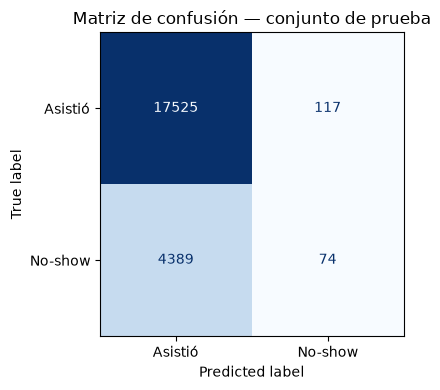

In [35]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

y_pred = modelo.predict(X_test)
y_proba = modelo.predict_proba(X_test)[:, 1]

metricas = {
    "accuracy":  accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall":    recall_score(y_test, y_pred),
    "f1":        f1_score(y_test, y_pred),
    "roc_auc":   roc_auc_score(y_test, y_proba),
}
for k, v in metricas.items():
    print(f"{k:>10}: {v:.4f}")

# Matriz de confusión (se guarda como imagen para registrarla en MLflow)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Asistió", "No-show"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión — conjunto de prueba")
plt.tight_layout()
fig.savefig("confusion_matrix.png", dpi=120)
plt.show()

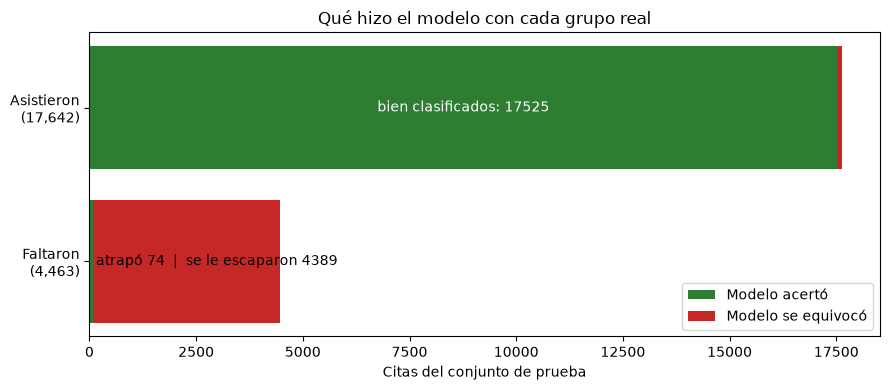

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
vn, fp = cm[0]   # fila "Asistió": bien clasificados, falsas alarmas
fn, vp = cm[1]   # fila "No-show": escapados, atrapados

fig, ax = plt.subplots(figsize=(9, 4))

# Barra 1: pacientes que FALTARON (realidad)
ax.barh("Faltaron\n(4,463)", vp, color="#2e7d32", label="Modelo acertó")
ax.barh("Faltaron\n(4,463)", fn, left=vp, color="#c62828", label="Modelo se equivocó")

# Barra 2: pacientes que ASISTIERON (realidad)
ax.barh("Asistieron\n(17,642)", vn, color="#2e7d32")
ax.barh("Asistieron\n(17,642)", fp, left=vn, color="#c62828")

# Etiquetas con los números
ax.text(vp + 80, 0, f"atrapó {vp}  |  se le escaparon {fn}", va="center")
ax.text(vn / 2, 1, f"bien clasificados: {vn}", va="center", ha="center", color="white")

ax.set_xlabel("Citas del conjunto de prueba")
ax.set_title("Qué hizo el modelo con cada grupo real")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretación detallada:**

- **Accuracy 79.6% — una métrica engañosa:** La accuracy salió alta, pero está inflada por los verdaderos negativos, es decir, por acertar la clase mayoritaria que asiste, que no es la que nos interesa predecir.

- **Recall 1.7% — el fallo central:** De los 4,463 que no asistieron reales, el modelo apenas detectó 74. Es decir, un 1.7% real detectado de lo que me interesa predecir con este modelo.

- **Precision 38.7%:** de cada 10 alarmas de no show que produce el modelo, apenas 4 son reales aciertos.
 
- **ROC-AUC 0.66:** el modelo sí ordena el riesgo mejor que el azar; el problema no es
  ausencia de señal sino el umbral de decisión. Operativamente serviría más como
  *ranking* de citas a reforzar que como clasificador duro.

**Conclusión del baseline:** queda registrado como punto de partida. Los
siguientes pasos  —ponderar clases (`class_weight="balanced"`), ajustar el
umbral según el costo real de cada error, o modelos no lineales— tendrán un número
claro contra el cual demostrar mejora.

## Paso 6 — Registro del experimento en MLflow

Registramos parámetros, métricas y artefactos (matriz de confusión y modelo serializado)
en MLflow Tracking local (`./mlruns`). La UI se abre con `mlflow ui`.

In [37]:
import mlflow
import mlflow.sklearn

mlflow.set_experiment("baseline-noshow-citas")

with mlflow.start_run(run_name="logreg-baseline") as run:
    # Parámetros: configuración del experimento
    mlflow.log_param("modelo", "LogisticRegression")
    mlflow.log_param("class_weight", None)
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param("estratificado", True)
    mlflow.log_param("seed", SEED)
    mlflow.log_param("registros_entrenamiento", len(X_train))
    mlflow.log_param("dataset", "Medical Appointment No-Shows (Kaggle, 110,521 tras limpieza)")

    # Métricas de evaluación
    mlflow.log_metrics(metricas)

    # Artefactos: matriz de confusión + pipeline completo serializado
    mlflow.log_artifact("confusion_matrix.png")
    mlflow.sklearn.log_model(modelo, name="modelo_baseline")

    print("Run registrado | Run ID:", run.info.run_id)

2026/10/03 22:13:14 INFO mlflow.tracking.fluent: Experiment with name 'baseline-noshow-citas' does not exist. Creating a new experiment.


Run registrado | Run ID: 06e2c0f6483542b6b84fcfb20de7e886


In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Mismo pipeline, un solo cambio: class_weight="balanced"
modelo_bal = Pipeline(steps=[
    ("preprocesador", preproc),
    ("clasificador", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
])

modelo_bal.fit(X_train, y_train)
y_pred_bal = modelo_bal.predict(X_test)
y_proba_bal = modelo_bal.predict_proba(X_test)[:, 1]

metricas_bal = {
    "accuracy": accuracy_score(y_test, y_pred_bal),
    "precision": precision_score(y_test, y_pred_bal),
    "recall": recall_score(y_test, y_pred_bal),
    "f1": f1_score(y_test, y_pred_bal),
    "roc_auc": roc_auc_score(y_test, y_proba_bal),
}

for k, v in metricas_bal.items():
    print(f"{k:>10}: {v:.4f}")

with mlflow.start_run(run_name="logreg-balanced") as run:
    mlflow.log_param("modelo", "LogisticRegression")
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param("estratificado", True)
    mlflow.log_param("seed", SEED)
    mlflow.log_param("registros_entrenamiento", len(X_train))
    mlflow.log_param("dataset", "Medical Appointment No-Shows (Kaggle, 110,521 tras limpieza)")
    mlflow.log_metrics(metricas_bal)
    mlflow.sklearn.log_model(modelo_bal, name="modelo_balanced")
    print("Run registrado | Run ID:", run.info.run_id)

  accuracy: 0.6532
 precision: 0.3085
    recall: 0.5783
        f1: 0.4024
   roc_auc: 0.6646
Run registrado | Run ID: e450ce8e3d4344b3bac1cc0f606d5be3


**Comparación de los dos experimentos:**

| Métrica | logreg-baseline | logreg-balanced | Cambio |
|---|---|---|---|
| Accuracy | 0.7962 | 0.6532 | ↓ 14 puntos |
| Precision | 0.3874 | 0.3085 | ↓ leve |
| Recall | 0.0166 | **0.5783** | **×35** |
| F1 | 0.0318 | 0.4024 | de inútil a razonable |
| ROC-AUC | 0.6588 | 0.6646 | sin cambio real |

**Lectura:**

- El único cambio entre ambos runs es `class_weight="balanced"`: le indicamos al modelo
  que dejar escapar un no-show pesa más que dar una falsa alarma.
- **El recall se multiplicó por 35** (de detectar 74 ausencias a detectar ~2,580 de las
  4,463 reales). A cambio, la precision bajó: el modelo ahora es generoso con las alarmas
  y acierta menos por cada una — la tensión precision/recall en acción.
- **La accuracy bajó 14 puntos y eso no significa que el modelo empeoró.** Al contrario:
  pasó de inútil a operativamente usable. La accuracy premiaba al modelo que casi nunca
  predecía no-show, porque acertar la clase mayoritaria es fácil. Esta es la evidencia
  definitiva de por qué no puede ser la métrica de decisión en problemas desbalanceados.
- **El ROC-AUC casi no se movió** (0.659 → 0.665): la capacidad del modelo de *ordenar*
  pacientes por riesgo es la misma. `class_weight` no lo hizo más inteligente, solo
  movió el punto de corte — lo hizo menos tímido para declarar no-show.



## Captura del experimento registrado en MLFlow

Se registran 2 corridas, y dentro de cada corrida se pueden ver sus diferencias en cuanto a las métricas.

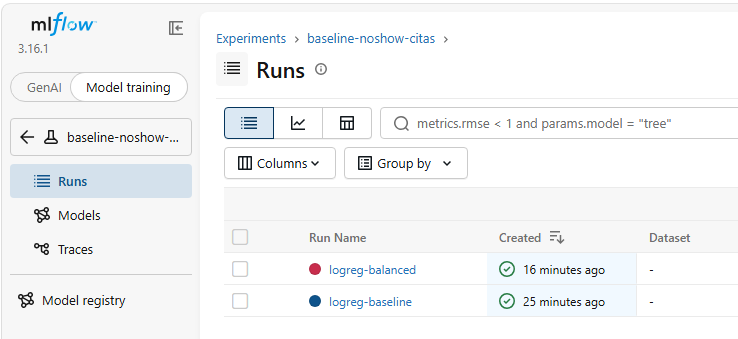

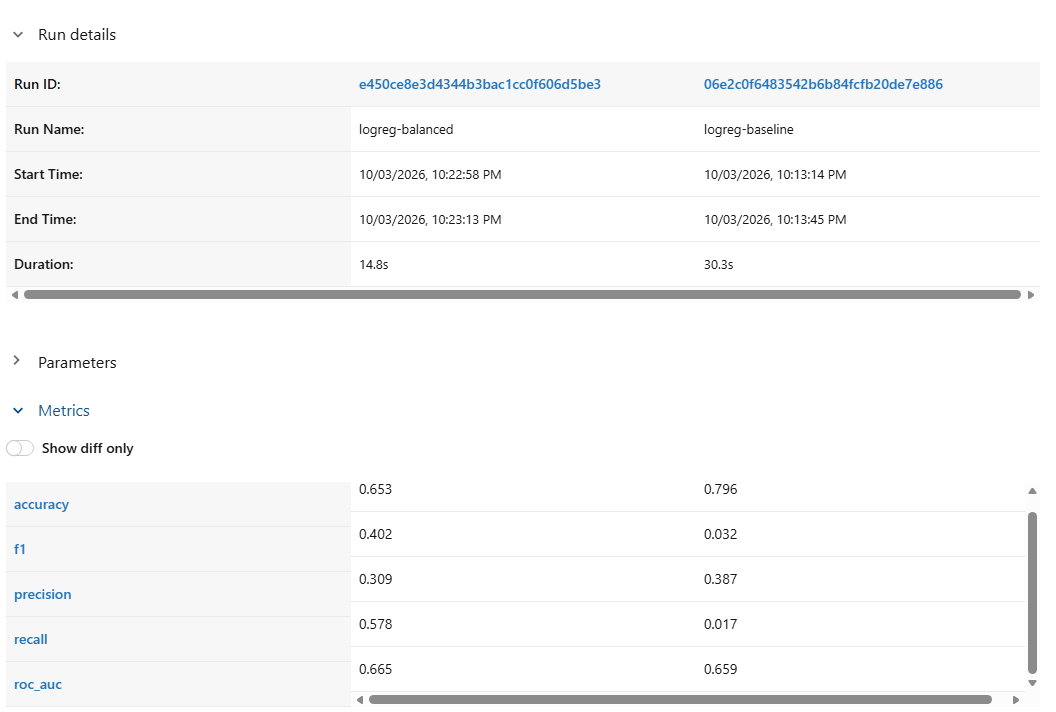

## Reflexión

Para quienes estamos empezando en el mundo de la ciencia de datos y el machine learning, la variedad de conceptos por aprender es enorme: matemáticas, programación y ahora, con MLOps, también infraestructura, servidores, nube y cómo conectar todo. Es un paso grande y un reto grande. En mi caso, la parte de "Operations" no es nueva, porque la he vivido en DevOps y en la operación del negocio, pero MLOps me está resultando muy interesante y, sobre todo, útil para aplicarlo en mi día a día laboral ahora que empiezo a llevar lo aprendido en la maestría a la empresa.

Este notebook me hizo evidente algo que hoy me sucede con el modelo de churn que tenemos en producción desde hace poco: un modelo lo pruebo "si funciona o no" cuando ya está en producción. No he guardado información histórica de qué métricas produjo cada versión, qué hiperparámetros se usaron, con qué datos se entrenó ni en qué fechas. No he documentado el proceso; me he preocupado únicamente por tener un modelo que reciba entradas y produzca una salida.

Con lo visto en esta actividad, mejoraría el flujo en cuatro frentes. Primero, registrar cada entrenamiento en MLflow, como hice aquí con los runs baseline y balanced, para comparar versiones con datos y no de memoria. Segundo, versionar el dataset con DVC, porque el modelo depende tanto de los datos como del código. Tercero, usar el Model Registry para saber con certeza qué versión está en producción y poder volver atrás. Cuarto, monitorear el modelo en producción con Evidently para detectar deriva y decidir cuándo reentrenar, en lugar de descubrirlo tarde. 

MLOps me abre la puerta a algo que considero vital en cualquier proyecto serio de machine learning que quiera salir a producción.